# 07. Avaliação do modelo final

O notebook `06_olhos_fechados` escolheu o modelo final pela validação: o **013** (sobreamostragem
×8 dos olhos fechados, peso 8 nos pontos dos olhos, augmentation de baixa resolução e 80 épocas).
Aqui ele passa pela mesma avaliação completa do `05_avaliacao`, no **teste oficial** do WFLW
(2.500 faces) com as mesmas medidas, agora com a **média com a face espelhada (TTA)**
ligada, como no `predict.py` e no `app.py`.

1. Carregar o modelo e prever o teste
2. NME geral e taxa de falha
3. NME por tipo de dificuldade e por região da face
4. A curva de erro acumulado
5. A abertura dos olhos: EAR anotado contra EAR previsto
6. Olhos fechados
7. Exemplos de acertos e de falhas
8. O caminho completo com o detector YuNet, como na aplicação, e o tempo por imagem

In [1]:
import os
import time
from collections import defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn
from torch.nn import functional as F

plt.rcParams["figure.dpi"] = 90

# raiz do projeto (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"                      # WFLW (espelho público no Kaggle, ver o README)
ANN, IMG = DATA / "WFLW_annotations", DATA / "WFLW_images"
PROCESSED = DATA / "processed"            # saídas do notebook 02

RUN = os.environ.get("NB_RUN", "fera/013_final_strong_lowres")
CKPT = ROOT / "runs" / RUN / "best.pt"
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
MIRROR = np.array((ANN / "Mirror98.txt").read_text().strip().split(","), dtype=int)
print("checkpoint:", CKPT.relative_to(ROOT), "| existe:", CKPT.exists())

checkpoint: runs/fera/013_final_strong_lowres/best.pt | existe: True


In [2]:
class LandmarkNet(nn.Module):
    """Backbone pré-treinado (sem pooling e FC) + cabeça de landmarks própria."""

    def __init__(self, num_landmarks=98, pretrained=True, head_channels=256, num_deconv=3):
        super().__init__()
        resnet = torchvision.models.resnet18(
            weights=torchvision.models.ResNet18_Weights.DEFAULT if pretrained else None)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])   # remove avgpool e fc

        layers, c_in = [], 512
        for _ in range(num_deconv):            # 8 -> 16 -> 32 -> 64
            layers += [nn.ConvTranspose2d(c_in, head_channels, 4, stride=2, padding=1, bias=False),
                       nn.BatchNorm2d(head_channels), nn.ReLU(inplace=True)]
            c_in = head_channels
        layers.append(nn.Conv2d(head_channels, num_landmarks, 1))   # 1 mapa por landmark
        self.head = nn.Sequential(*layers)
        for m in self.head.modules():
            if isinstance(m, (nn.ConvTranspose2d, nn.Conv2d)):
                nn.init.normal_(m.weight, std=0.001)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
        self.stride = 32 // (2 ** num_deconv)  # pixels da entrada por célula do mapa (4)

    def forward(self, x):
        logits = self.head(self.backbone(x))
        return soft_argmax(logits, self.stride), logits


def soft_argmax(logits, stride):
    """Coordenada esperada sob um softmax espacial, em pixels da entrada."""
    b, k, h, w = logits.shape
    prob = F.softmax(logits.reshape(b, k, h * w).float(), dim=-1).reshape(b, k, h, w)
    xs = torch.arange(w, device=logits.device, dtype=prob.dtype)
    ys = torch.arange(h, device=logits.device, dtype=prob.dtype)
    x = (prob.sum(2) * xs).sum(-1)
    y = (prob.sum(3) * ys).sum(-1)
    # a célula i cobre os pixels [stride·i, stride·i + stride − 1]; centro = stride·i + (stride − 1)/2
    return torch.stack([x, y], -1) * stride + (stride - 1) / 2

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], np.float32)


def to_tensor(image_rgb):
    # (H, W, 3) uint8 RGB -> (3, H, W) float normalizado como na ImageNet
    x = (image_rgb.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())

EAR_RIGHT = (60, 61, 63, 64, 65, 67)   # p1..p6 do olho direito da pessoa
EAR_LEFT = (72, 71, 69, 68, 75, 73)    # espelho pelo Mirror98


def ear_eye(p, idx):
    p1, p2, p3, p4, p5, p6 = (p[..., i, :] for i in idx)
    n = lambda a, b: np.linalg.norm(a - b, axis=-1)
    return (n(p2, p6) + n(p3, p5)) / (2 * n(p1, p4) + 1e-9)


def ear(p):
    return (ear_eye(p, EAR_RIGHT) + ear_eye(p, EAR_LEFT)) / 2

REGIONS = {
    "contorno": range(0, 33), "sobrancelhas": range(33, 51), "nariz": range(51, 60),
    "olhos": range(60, 76), "boca": range(76, 96), "pupilas": range(96, 98),
}
EYES = list(range(60, 76))


def point_errors(pred, gt):
    # erro de cada ponto dividido pela distância entre os cantos externos dos olhos (60-72)
    d = np.linalg.norm(gt[:, 60] - gt[:, 72], axis=-1)
    return np.linalg.norm(pred - gt, axis=-1) / d[:, None]


def nme(pred, gt, points=None):
    e = point_errors(pred, gt)
    return e.mean(-1) if points is None else e[:, list(points)].mean(-1)


def summary(pred, gt):
    per_face = nme(pred, gt)
    e_gt, e_pred = ear(gt), ear(pred)
    return {"nme": per_face.mean(), "fr10": (per_face > 0.10).mean(),
            "eye_nme": nme(pred, gt, EYES).mean(),
            "ear_corr": np.corrcoef(e_gt, e_pred)[0, 1], "ear_mae": np.abs(e_gt - e_pred).mean()}

ATTRIBUTES = ["pose", "expressão", "iluminação", "maquiagem", "oclusão", "desfoque"]


@torch.no_grad()
def run_model(net, x):
    """Média da previsão com a da face espelhada (TTA), desfazendo o espelhamento com o Mirror98."""
    p = net(x)[0].float().cpu().numpy()
    q = net(torch.flip(x, dims=[3]))[0].float().cpu().numpy()
    q[..., 0] = x.shape[3] - 1 - q[..., 0]
    return (p + q[:, MIRROR]) / 2


## 1. O modelo e as previsões no teste

In [3]:
ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)
mc = ckpt["config"]["model"]
model = LandmarkNet(pretrained=False, head_channels=mc["head_channels"], num_deconv=mc["num_deconv"])
model.load_state_dict(ckpt["model"])
model.eval().to(DEVICE)
print(f"época {ckpt['epoch']} | NME de validação {100 * ckpt['val']['nme']:.2f} %")

SIZE, OFF = ckpt["input_size"], (384 - ckpt["input_size"]) // 2   # centro 256 do cache = recorte de entrada
crops = np.load(PROCESSED / "test_crops.npy", mmap_mode="r")
meta = np.load(PROCESSED / "test_meta.npz")
gt = meta["landmarks"].astype(np.float64) - OFF
attrs = meta["attributes"]

preds = []
with torch.no_grad():
    for s in range(0, len(gt), 64):
        x = torch.stack([to_tensor(np.asarray(c)[OFF:OFF + SIZE, OFF:OFF + SIZE]) for c in crops[s:s + 64]])
        preds.append(run_model(model, x.to(DEVICE)))
pred = np.concatenate(preds).astype(np.float64)
print("previsões:", pred.shape)

época 69 | NME de validação 4.17 %


previsões: (2500, 98, 2)


## 2. NME geral e taxa de falha

In [4]:
per_face = nme(pred, gt)
eye = nme(pred, gt, EYES)
s = summary(pred, gt)
print(f"NME global:          {100 * s['nme']:.2f} %")
print(f"taxa de falha (>10%): {100 * s['fr10']:.2f} %")
print(f"NME olhos:           {100 * s['eye_nme']:.2f} %")
print(f"falha olhos (>10%):  {100 * (eye > 0.10).mean():.2f} %")

NME global:          5.12 %
taxa de falha (>10%): 6.68 %
NME olhos:           3.27 %
falha olhos (>10%):  3.16 %


## 3. Por tipo de dificuldade e por região da face

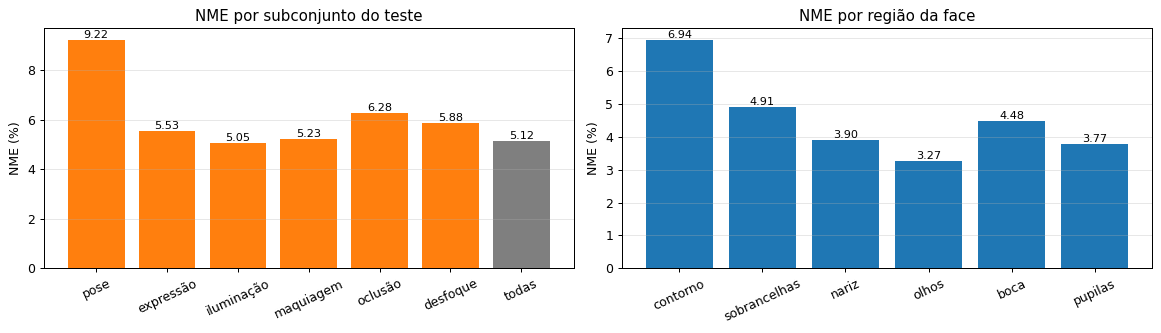

In [5]:
subset = {a: 100 * per_face[attrs[:, j] == 1].mean() for j, a in enumerate(ATTRIBUTES)}
subset["todas"] = 100 * per_face.mean()
pe = point_errors(pred, gt)
region = {r: 100 * pe[:, list(idx)].mean() for r, idx in REGIONS.items()}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(subset.keys(), subset.values(), color=["tab:orange"] * 6 + ["tab:gray"])
axes[0].set_ylabel("NME (%)"); axes[0].set_title("NME por subconjunto do teste")
axes[1].bar(region.keys(), region.values(), color="tab:blue")
axes[1].set_ylabel("NME (%)"); axes[1].set_title("NME por região da face")
for ax, d in [(axes[0], subset), (axes[1], region)]:
    for k, (name, v) in enumerate(d.items()):
        ax.annotate(f"{v:.2f}", (k, v), ha="center", va="bottom", fontsize=9)
    ax.tick_params(axis="x", rotation=25); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

## 4. A curva de erro acumulado

Para cada valor de NME, a curva mostra que fração das faces tem erro até aquele valor. A linha
tracejada marca o limite de falha, 10 %.

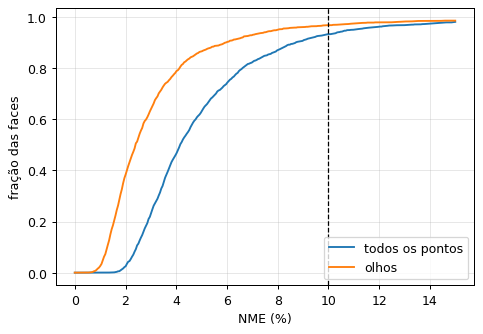

In [6]:
ts = np.linspace(0, 0.15, 300)
plt.figure(figsize=(6, 4))
for name, v in [("todos os pontos", per_face), ("olhos", eye)]:
    plt.plot(100 * ts, [(v <= t).mean() for t in ts], label=name)
plt.axvline(10, c="k", ls="--", lw=1)
plt.xlabel("NME (%)"); plt.ylabel("fração das faces"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 5. A abertura dos olhos: EAR anotado contra EAR previsto

O NME diz se os pontos estão no lugar certo, mas para a sonolência o que importa é a
**abertura** do olho. Então comparamos o EAR calculado com os pontos previstos e com os pontos
anotados.

correlação (Pearson) = 0.725 | MAE = 0.0475 | reta: EAR_prev = 0.65·EAR_anot + 0.08


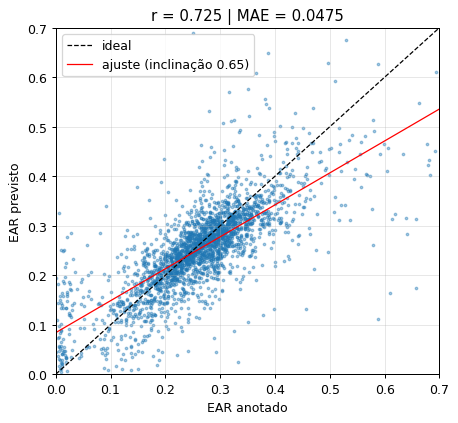

In [7]:
e_gt, e_pred = ear(gt), ear(pred)
r = np.corrcoef(e_gt, e_pred)[0, 1]
mae = np.abs(e_gt - e_pred).mean()
a, b = np.polyfit(e_gt, e_pred, 1)
print(f"correlação (Pearson) = {r:.3f} | MAE = {mae:.4f} | reta: EAR_prev = {a:.2f}·EAR_anot + {b:.2f}")

plt.figure(figsize=(5.5, 5))
plt.scatter(e_gt, e_pred, s=4, alpha=0.4)
lim = [0, 0.7]
plt.plot(lim, lim, "k--", lw=1, label="ideal")
plt.plot(lim, [a * v + b for v in lim], "r-", lw=1, label=f"ajuste (inclinação {a:.2f})")
plt.xlim(lim); plt.ylim(lim); plt.xlabel("EAR anotado"); plt.ylabel("EAR previsto")
plt.title(f"r = {r:.3f} | MAE = {mae:.4f}"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 6. Olhos fechados (EAR anotado abaixo de 0,15)

In [8]:
closed, opened = e_gt < 0.15, e_gt >= 0.25
print(f"faces com olhos fechados: {closed.sum()}")
print(f"  EAR anotado médio:  {e_gt[closed].mean():.3f}")
print(f"  EAR previsto médio: {e_pred[closed].mean():.3f}")
print(f"  NME olhos:          {100 * eye[closed].mean():.2f} % (total: {100 * eye.mean():.2f} %)")
print(f"  fechados previstos como fechados (EAR < 0,15): {100 * (e_pred[closed] < 0.15).mean():.1f} %")
print(f"  abertos previstos como fechados:               {100 * (e_pred[opened] < 0.15).mean():.1f} %")

faces com olhos fechados: 274
  EAR anotado médio:  0.082
  EAR previsto médio: 0.127
  NME olhos:          4.01 % (total: 3.27 %)
  fechados previstos como fechados (EAR < 0,15): 67.5 %
  abertos previstos como fechados:               1.3 %


No baseline (`05_avaliacao`), o EAR previsto dos olhos fechados ficava em torno de 0,19 e só cerca
de 20 % deles eram reconhecidos como fechados. Compare com os números acima: é a melhora que o
modelo final traz para a detecção de sonolência, ao custo de marcar alguns olhos abertos como
fechados (a linha "abertos previstos como fechados").

## 7. Exemplos de acertos e de falhas

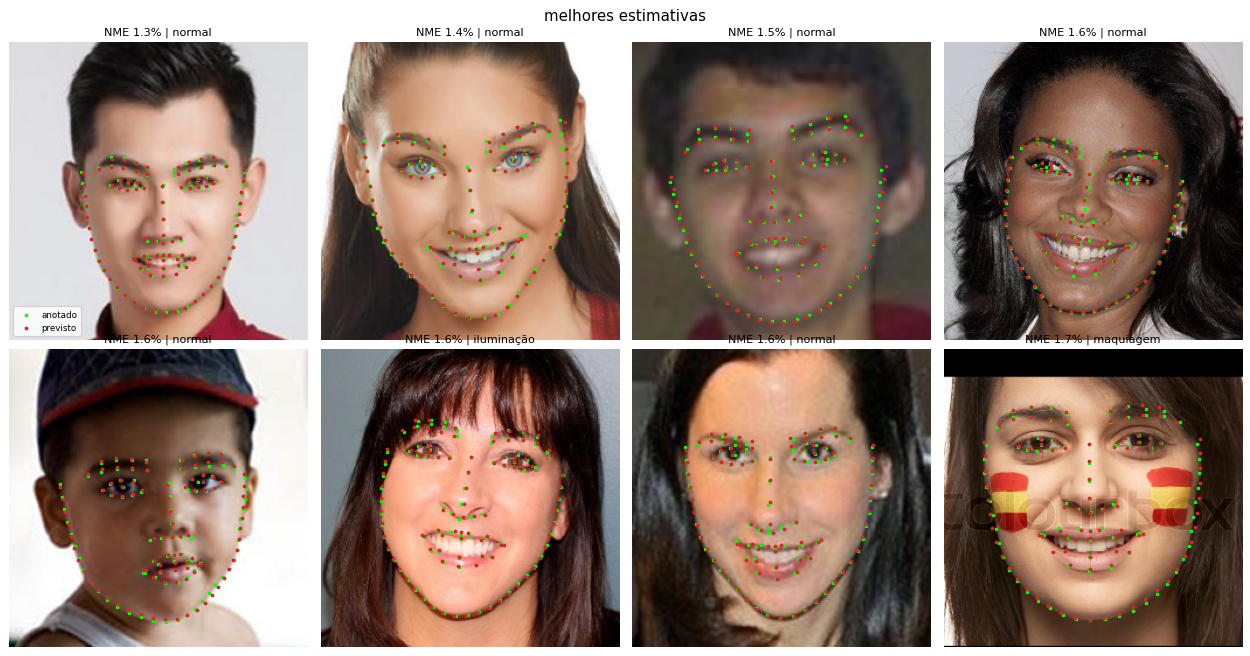

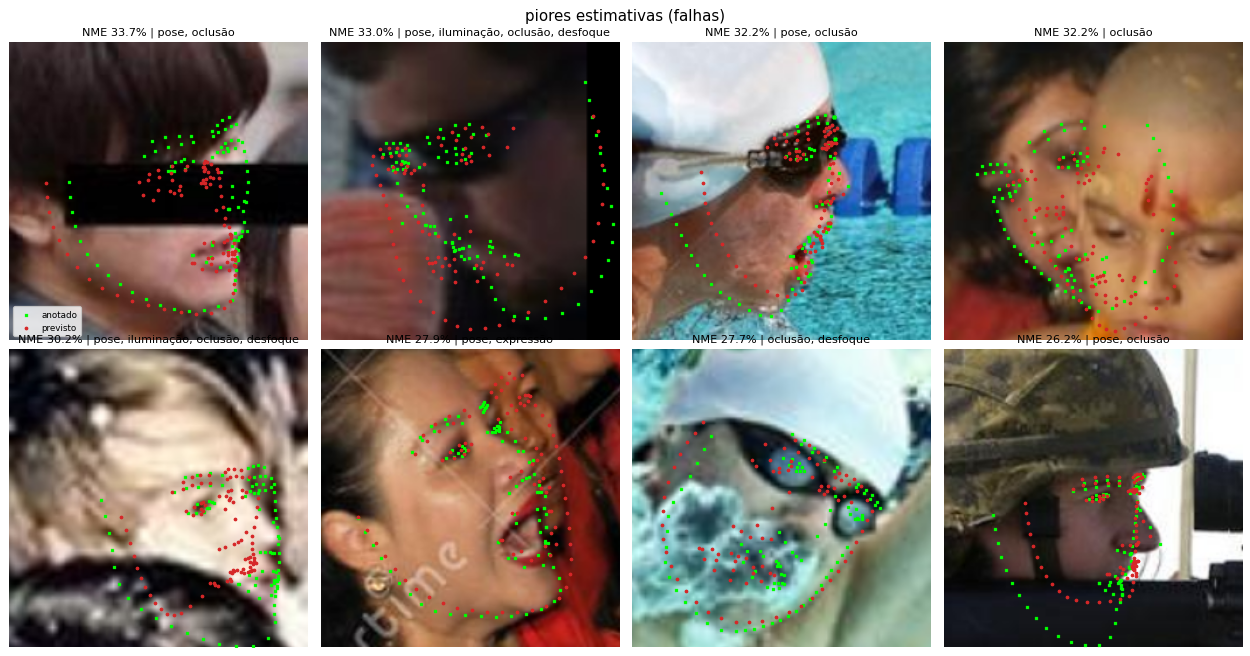

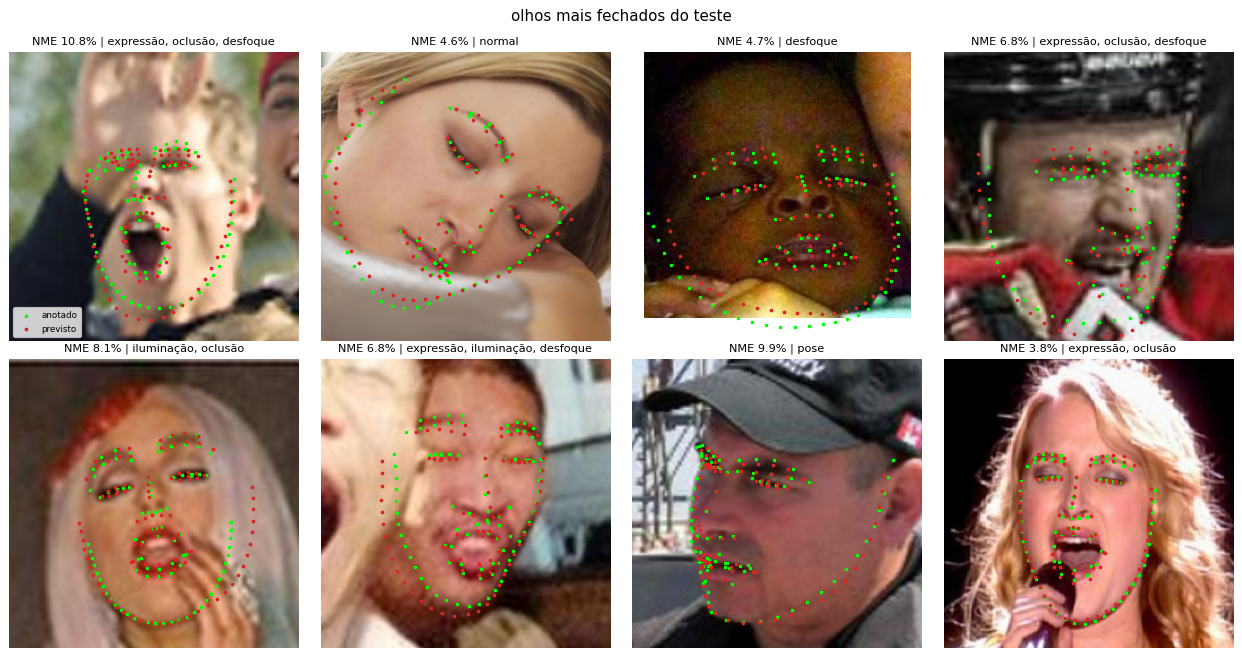

In [9]:
def show(indices, title):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.4))
    for ax, k in zip(axes.flat, indices):
        im = np.asarray(crops[k])[OFF:OFF + SIZE, OFF:OFF + SIZE]
        ax.imshow(im)
        ax.scatter(gt[k, :, 0], gt[k, :, 1], s=4, c="lime", marker="x", label="anotado")
        ax.scatter(pred[k, :, 0], pred[k, :, 1], s=4, c="tab:red", label="previsto")
        on = [ATTRIBUTES[j] for j in range(6) if attrs[k, j]]
        ax.set_title(f"NME {100 * per_face[k]:.1f}% | {', '.join(on) or 'normal'}", fontsize=9); ax.axis("off")
    axes.flat[0].legend(loc="lower left", fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()


order = np.argsort(per_face)
show(order[:8], "melhores estimativas")
show(order[::-1][:8], "piores estimativas (falhas)")
show(np.where(closed)[0][np.argsort(e_gt[closed])][:8], "olhos mais fechados do teste")

## 8. O caminho completo com o detector YuNet

Na prática, o `predict(imagem)` recebe só a imagem, sem informar onde está a face, então
o modelo precisa **encontrar as faces sozinho**. Medimos assim:
para cada face anotada, pegamos a face prevista com o menor NME, e se esse NME passar de 50 % a
face conta como **não detectada**.

O YuNet desenha o retângulo da face do mesmo jeito que o WFLW, incluindo a testa, então a regra
de recorte do treino vale sem nenhuma mudança.

In [10]:
yunet = cv2.FaceDetectorYN.create(str(ROOT / "models" / "face_detection_yunet_2023mar.onnx"), "", (320, 320), 0.6, 0.3, 5000)
cpu_model = LandmarkNet(pretrained=False, head_channels=mc["head_channels"], num_deconv=mc["num_deconv"])
cpu_model.load_state_dict(ckpt["model"]); cpu_model.eval()
MARGIN = ckpt["margin"]


def detect(image_bgr, max_side=1600):
    h, w = image_bgr.shape[:2]
    s = min(1.0, max_side / max(h, w))
    small = image_bgr if s == 1.0 else cv2.resize(image_bgr, None, fx=s, fy=s)
    yunet.setInputSize((small.shape[1], small.shape[0]))
    _, faces = yunet.detect(small)
    if faces is None:
        return np.zeros((0, 4))
    x, y, bw, bh = (faces[:, j] / s for j in range(4))
    return np.stack([x, y, x + bw, y + bh], 1)


def crop_matrix(box, size, margin):
    x0, y0, x1, y1 = [float(v) for v in box]
    c = np.array([(x0 + x1) / 2, (y0 + y1) / 2])
    sc = size / (margin * max(x1 - x0, y1 - y0))
    return np.array([[sc, 0, size / 2 - sc * c[0]], [0, sc, size / 2 - sc * c[1]]])


@torch.no_grad()
def predict_image(image_rgb):
    boxes = detect(cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR))
    if len(boxes) == 0:
        return np.zeros((0, 98, 2))
    mats = [crop_matrix(b, SIZE, MARGIN) for b in boxes]
    x = torch.stack([to_tensor(cv2.warpAffine(image_rgb, m, (SIZE, SIZE), flags=cv2.INTER_LINEAR)) for m in mats])
    pts = run_model(cpu_model, x).astype(np.float64)
    inv = [cv2.invertAffineTransform(m) for m in mats]
    return np.stack([p @ mi[:, :2].T + mi[:, 2] for p, mi in zip(pts, inv)])


by_image = defaultdict(list)
for k, rel in enumerate(meta["images"]):
    by_image[str(rel)].append(meta["landmarks_orig"][k].astype(np.float64))

nmes, eyes_, times, missed = [], [], [], 0
for rel, faces in by_image.items():
    image = cv2.cvtColor(cv2.imread(str(IMG / rel)), cv2.COLOR_BGR2RGB)
    t = time.perf_counter(); p = predict_image(image); times.append(time.perf_counter() - t)
    for g in faces:
        if len(p) == 0:
            missed += 1; continue
        all_nme = nme(p, np.broadcast_to(g, p.shape))
        j = int(np.argmin(all_nme))
        if all_nme[j] >= 0.5:
            missed += 1; continue
        nmes.append(all_nme[j]); eyes_.append(nme(p[j:j + 1], g[None], EYES)[0])

n = len(nmes) + missed
nmes, eyes_ = np.array(nmes), np.array(eyes_)
print(f"imagens: {len(by_image)} | faces anotadas: {n}")
print(f"faces detectadas:     {100 * len(nmes) / n:.2f} %")
print(f"NME (detectadas):     {100 * nmes.mean():.2f} %")
print(f"taxa de falha:        {100 * ((nmes > 0.1).sum() + missed) / n:.2f} %  (não detectadas contam como falha)")
print(f"NME olhos:            {100 * eyes_.mean():.2f} %")
print(f"tempo mediano/imagem: {1000 * np.median(times):.0f} ms na CPU (limite: 2000 ms)")

imagens: 2118 | faces anotadas: 2500
faces detectadas:     97.80 %
NME (detectadas):     5.08 %
taxa de falha:        8.40 %  (não detectadas contam como falha)
NME olhos:            3.14 %
tempo mediano/imagem: 150 ms na CPU (limite: 2000 ms)


## Conclusão

O modelo final mantém o NME geral perto do baseline e melhora bastante a medida dos olhos, que é
o que importa para a aplicação. Usando o retângulo do YuNet, o NME fica praticamente igual ao do
retângulo anotado, então o recorte da aplicação continua compatível com o do treino, e o tempo por
imagem fica bem abaixo do limite de 2 segundos mesmo com a rede rodando duas vezes (TTA).

Os números deste notebook vão para o relatório e para o card do modelo no Hugging Face.